# Phase 6 — 90-day lapse-risk modelling

**Fixed synthetic snapshot: 1 September 2026**

This notebook presents the frozen executed artifacts. It does **not** retrain, reselect, or
reevaluate the held-out test set. SQL reconstructed every historical row as of its observation
date; Python fitted on train, selected on validation, froze the choice, evaluated test once, and
only then scored the current portfolio.

Read the [model contract](../docs/phase6_model_definitions.md),
[panel checkpoint](../docs/phase6_panel_checkpoint.md), and
[executed findings](../docs/phase6_findings.md).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
ARTIFACTS = ROOT / "data/processed/phase6"
FIGURES = ARTIFACTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

metadata = json.loads((ARTIFACTS / "model_metadata.json").read_text())
panel = pd.read_csv(ARTIFACTS / "panel_summary.csv")
monthly = pd.read_csv(
    ARTIFACTS / "monthly_target_distribution.csv", parse_dates=["observation_date"]
)
metrics = pd.read_csv(ARTIFACTS / "model_metrics.csv")
topk = pd.read_csv(ARTIFACTS / "topk_metrics.csv")
calibration = pd.read_csv(ARTIFACTS / "calibration_summary.csv")
calibration_bins = pd.read_csv(ARTIFACTS / "calibration_bins.csv")
importance = pd.read_csv(ARTIFACTS / "feature_importance.csv")
fairness = pd.read_csv(ARTIFACTS / "fairness_diagnostics.csv")
validation_predictions = pd.read_csv(ARTIFACTS / "validation_predictions.csv")
test_predictions = pd.read_csv(ARTIFACTS / "test_predictions.csv")
current_scores = pd.read_csv(ARTIFACTS / "current_policy_scores.csv")

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
    }
)
BLUE, TEAL, ORANGE, RED, GREY = "#235789", "#187D78", "#C77727", "#B44C43", "#7A7A7A"


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)


display(
    pd.Series(
        {
            "Selected model": metadata["selected_model"],
            "Frozen before test": metadata["frozen_before_test"],
            "Test evaluated once": metadata["test_evaluated_once"],
            "Current scoring after test": metadata["current_scoring_after_test"],
            "SQL SHA-256": metadata["sql_sha256"],
            "Python SHA-256": metadata["python_sha256"],
        },
        name="Execution evidence",
    ).to_frame()
)

,Execution evidence
Selected model,random_forest
Frozen before test,True
Test evaluated once,True
Current scoring after test,True
SQL SHA-256,3a689e636196e0fa6a4cf3ca8bdba36bb1780a058b83e9...
Python SHA-256,61630212cec1fbc421339d512e56c4128f7012ea78a7c1...


## 1–4. Business problem, lapse meaning, prediction versus reporting, and target

The model estimates whether a policy that is in force at a historical month-end will enter
`Lapsed` status in the next 90 days. Unlike persistency reporting, this creates repeated forward-
looking risk assessments. A lapse strictly after observation and on or before day 90 is positive.

## 5–8. Observation dates, risk set, right censoring, and leakage

Rows are policy × month-end. Active, Grace, and chronologically Reinstated policies aged at least
30 days enter the risk set. Only observations with a fully visible 90-day future window are
labelled. Final policy status, future status events, future payments, stored final payment status,
identifiers, gender, and Phase 5 segments are excluded from predictors.

## 9–12. Historical panel, features, payment reconstruction, and prevalence

Payment features use only installments due by observation and only receipts known by observation.
A later receipt cannot rewrite an earlier feature snapshot. The increasing monthly rate is a
central model-risk finding, not background noise.

,rows,unique_policies,observation_months,first_observation_date,last_observation_date,positives,positive_rate
0,403549,27837,40,2023-02-28,2026-05-31,7703,0.019088


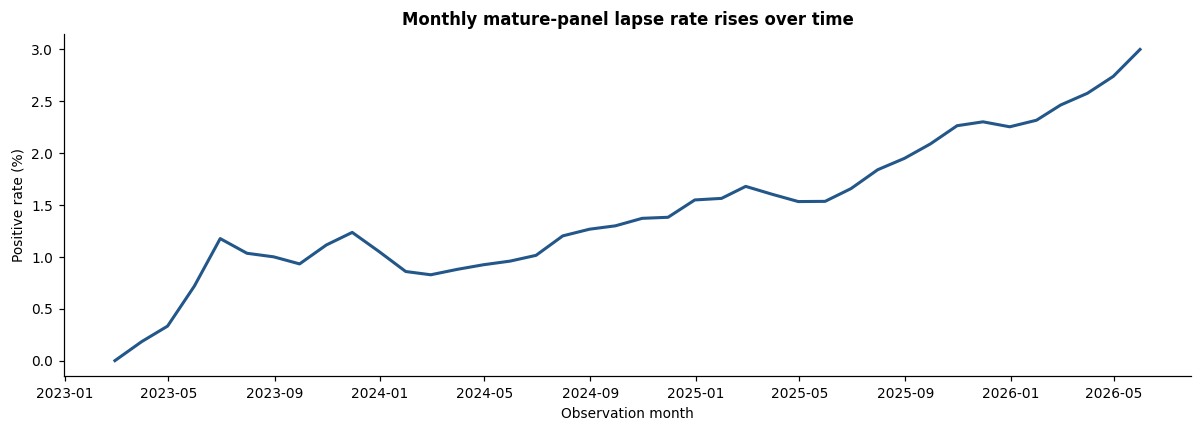

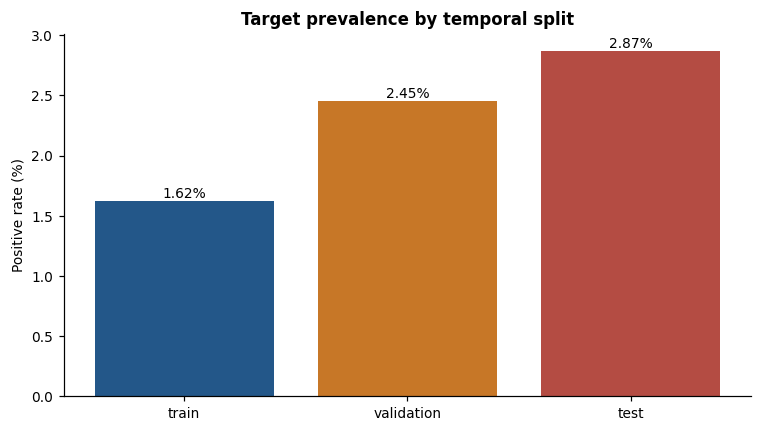

,split,first_observation_date,last_observation_date,rows,positives,positive_rate
0,train,2023-02-28,2025-12-31,288768,4683,0.016217
1,validation,2026-01-31,2026-03-31,65482,1606,0.024526
2,test,2026-04-30,2026-05-31,49299,1414,0.028682


In [2]:
display(panel)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.observation_date, monthly.positive_rate * 100, color=BLUE, linewidth=2)
ax.set(
    title="Monthly mature-panel lapse rate rises over time",
    xlabel="Observation month",
    ylabel="Positive rate (%)",
)
finish(fig, "01_monthly_positive_rate")

split = pd.DataFrame(metadata["split_summary"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(split["split"], split["positive_rate"] * 100, color=[BLUE, ORANGE, RED])
ax.set(title="Target prevalence by temporal split", ylabel="Positive rate (%)")
for i, row in split.iterrows():
    ax.text(i, row.positive_rate * 100, f"{row.positive_rate:.2%}", ha="center", va="bottom")
finish(fig, "02_target_class_balance")
display(split)

## 13. Locked temporal split

Train ends 31 December 2025, validation covers January–March 2026, and test covers April–May 2026.
The same policy may appear in multiple months; no random row split or random cross-validation is
used.

## 14–18. Base rate, Logistic Regression, challenger, validation, and frozen choice

The base-rate benchmark predicts train prevalence. Logistic Regression supplies the interpretable
linear baseline. One Random Forest is the nonlinear challenger. Both were fitted on train only and
compared on validation only. Random Forest was frozen because its validation PR-AUC and top-K
capture materially exceeded Logistic Regression under the predeclared simplicity rule.

In [3]:
display(
    metrics.query("dataset == 'validation'")[
        ["model", "pr_auc", "roc_auc", "brier_score", "mean_predicted_risk", "observed_rate"]
    ]
)
display(topk.query("dataset == 'validation'")[["model", "k_percent", "recall_at_k", "lift_at_k"]])
print(metadata["selection_reason"])
print("Frozen operational cutoff:", metadata["operational_cutoff"])

,model,pr_auc,roc_auc,brier_score,mean_predicted_risk,observed_rate
0,base_rate,0.024526,0.500000,0.023993,0.016217,0.024526
1,logistic_regression,0.031491,0.575516,0.023977,0.015157,0.024526
2,random_forest,0.034204,0.592681,0.023948,0.015710,0.024526


,model,k_percent,recall_at_k,lift_at_k
0,base_rate,5,0.047945,0.958641
1,base_rate,10,0.096513,0.965013
2,base_rate,20,0.181196,0.905936
3,logistic_regression,5,0.080946,1.618484
4,logistic_regression,10,0.152553,1.525343
5,logistic_regression,20,0.254670,1.273292
6,random_forest,5,0.097136,1.942181
7,random_forest,10,0.163138,1.631183
8,random_forest,20,0.294521,1.472535


Random Forest delivered a material validation PR-AUC advantage; validation top-K capture, calibration, and permutation importance were reviewed separately.
Frozen operational cutoff: 0.02201304877088594


## 19–20. Held-out test and precision–recall analysis

The selected train-only model was evaluated once on test. The replacement execution persisted
this result immediately. PR-AUC is interpreted relative to test prevalence; modest improvement
over prevalence is not production-grade evidence.

,Frozen test
dataset,test
model,random_forest
pr_auc,0.034209
roc_auc,0.560633
precision,0.035857
recall,0.126591
f1,0.055885
threshold,0.022013
true_negative,43072
false_positive,4813


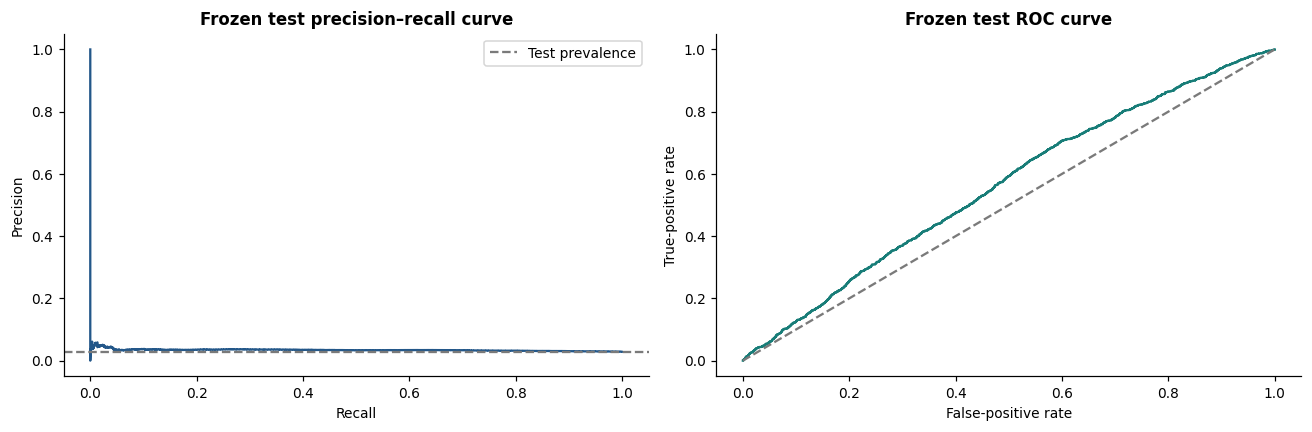

In [4]:
test_row = metrics.query("dataset == 'test'")
display(test_row.T.rename(columns={test_row.index[0]: "Frozen test"}))

y = test_predictions.lapse_next_90d.to_numpy()
p = test_predictions.risk_score.to_numpy()
precision, recall, _ = precision_recall_curve(y, p)
fpr, tpr, _ = roc_curve(y, p)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(recall, precision, color=BLUE)
axes[0].axhline(y.mean(), color=GREY, linestyle="--", label="Test prevalence")
axes[0].set(title="Frozen test precision–recall curve", xlabel="Recall", ylabel="Precision")
axes[0].legend()
axes[1].plot(fpr, tpr, color=TEAL)
axes[1].plot([0, 1], [0, 1], color=GREY, linestyle="--")
axes[1].set(
    title="Frozen test ROC curve",
    xlabel="False-positive rate",
    ylabel="True-positive rate",
)
finish(fig, "03_test_pr_roc")

## 21. Top-K capture and lift

Capacity metrics ask how many actual lapses appear in the highest-scored operational slice. They
are ranking measures and do not imply calibrated probabilities.

,dataset,model,k_percent,selected_rows,captured_positives,recall_at_k,lift_at_k
9,test,random_forest,5,2465,84,0.059406,1.188095
10,test,random_forest,10,4930,175,0.123762,1.237599
11,test,random_forest,20,9860,356,0.251768,1.258815


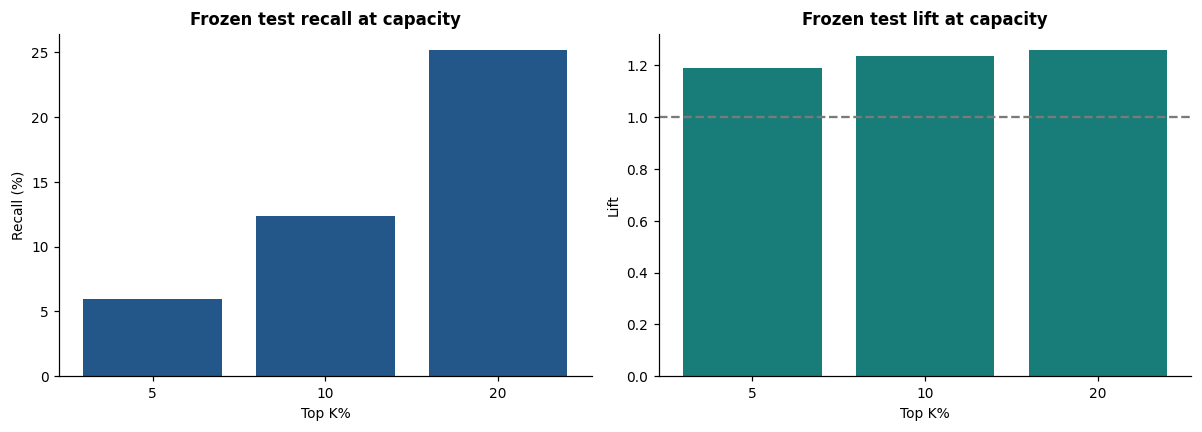

In [5]:
test_topk = topk.query("dataset == 'test'")
display(test_topk)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(test_topk.k_percent.astype(str), test_topk.recall_at_k * 100, color=BLUE)
axes[0].set(title="Frozen test recall at capacity", xlabel="Top K%", ylabel="Recall (%)")
axes[1].bar(test_topk.k_percent.astype(str), test_topk.lift_at_k, color=TEAL)
axes[1].axhline(1, color=GREY, linestyle="--")
axes[1].set(title="Frozen test lift at capacity", xlabel="Top K%", ylabel="Lift")
finish(fig, "04_test_topk")

## 22. Calibration—separate from discrimination

The model ranks above random yet underpredicts later absolute risk. On test, mean score is about
1.58% while observed lapse is 2.87%. Scores should therefore be communicated as prioritization
indices rather than exact probabilities.

,dataset,model,brier_score,mean_predicted_risk,observed_rate,calibration_in_the_large,calibration_intercept,calibration_slope,expected_calibration_error
0,validation,base_rate,0.023993,0.016217,0.024526,-0.008309,-3.683197,0.000000,0.008309
1,validation,logistic_regression,0.023977,0.015157,0.024526,-0.009369,-0.196835,0.834256,0.009369
2,validation,random_forest,0.023948,0.015710,0.024526,-0.008815,-0.198868,0.841151,0.008815
3,test,random_forest,0.027995,0.015763,0.028682,-0.012919,-0.192226,0.802576,0.012919


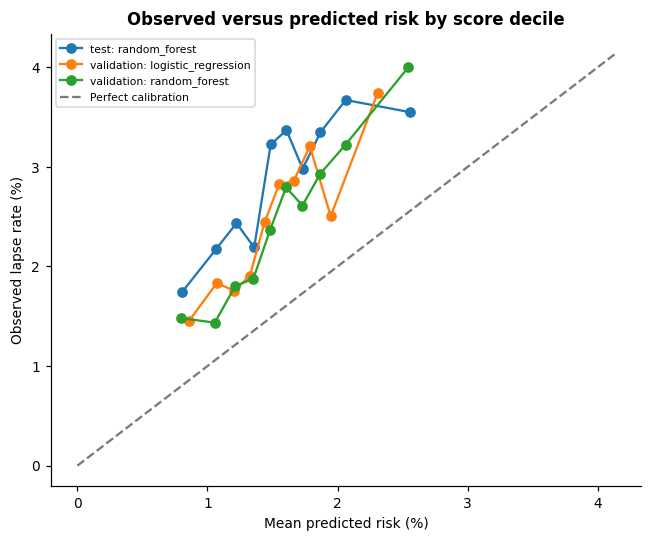

In [6]:
display(calibration)
fig, ax = plt.subplots(figsize=(6, 5))
for (dataset, model), subset in calibration_bins.groupby(["dataset", "model"]):
    if model == "base_rate":
        continue
    ax.plot(
        subset.mean_predicted_risk * 100,
        subset.observed_rate * 100,
        marker="o",
        label=f"{dataset}: {model}",
    )
limit = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, limit], [0, limit], color=GREY, linestyle="--", label="Perfect calibration")
ax.set(
    title="Observed versus predicted risk by score decile",
    xlabel="Mean predicted risk (%)",
    ylabel="Observed lapse rate (%)",
)
ax.legend(fontsize=7)
finish(fig, "05_calibration")

## 23. Explainability

Permutation importance measures validation PR-AUC change when a raw feature is shuffled. Small or
negative values can reflect sampling variation and interactions. They must not be interpreted as
causal effects.

,model,method,feature,importance,absolute_importance,importance_std
72,random_forest,validation_permutation_pr_auc,days_since_last_payment,0.001403,0.001403,0.000207
73,random_forest,validation_permutation_pr_auc,age_at_issue,0.001230,0.001230,0.000023
74,random_forest,validation_permutation_pr_auc,paid_count_to_date,0.001196,0.001196,0.000768
75,random_forest,validation_permutation_pr_auc,premium_amount,0.001182,0.001182,0.000210
76,random_forest,validation_permutation_pr_auc,amount_due_to_date,-0.001175,0.001175,0.001293
77,random_forest,validation_permutation_pr_auc,annualized_premium,0.001170,0.001170,0.000015
78,random_forest,validation_permutation_pr_auc,sum_assured,-0.001166,0.001166,0.000253
79,random_forest,validation_permutation_pr_auc,amount_paid_to_date,0.001082,0.001082,0.000262
80,random_forest,validation_permutation_pr_auc,installments_due_to_date,0.000845,0.000845,0.000755
81,random_forest,validation_permutation_pr_auc,missed_count_to_date,0.000833,0.000833,0.000297


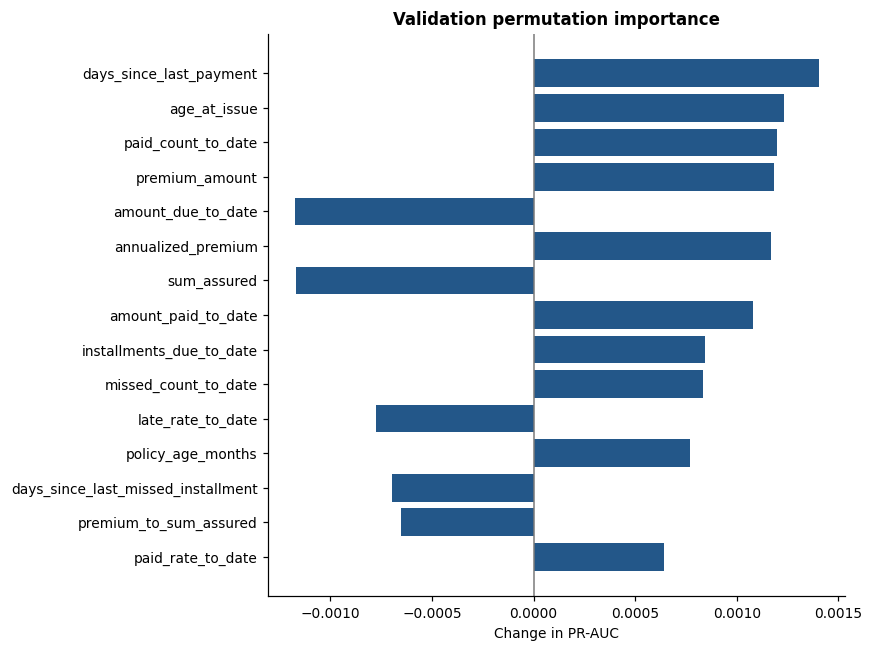

In [7]:
selected_name = metadata["selected_model"]
selected_importance = (
    importance.query("model == @selected_name")
    .sort_values("absolute_importance", ascending=False)
    .head(15)
    .sort_values("absolute_importance")
)
display(selected_importance.sort_values("absolute_importance", ascending=False))
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(selected_importance.feature, selected_importance.importance, color=BLUE)
ax.axvline(0, color=GREY, linewidth=1)
ax.set(title="Validation permutation importance", xlabel="Change in PR-AUC")
finish(fig, "06_feature_importance")

## 24. Descriptive fairness/model-risk diagnostics

Gender is not a predictor. Group metrics describe test behaviour and sample-size differences; they
are not legal fairness certification.

,attribute,group,sample_size,positives,positive_prevalence,average_predicted_risk,precision,recall,pr_auc
0,gender,Female,24226,666,0.027491,0.015738,0.030253,0.109610,0.032522
1,gender,Male,25073,748,0.029833,0.015787,0.041101,0.141711,0.036262
2,age_at_issue_band,25-34,10461,316,0.030207,0.015819,0.049866,0.177215,0.041381
3,age_at_issue_band,35-44,10291,301,0.029249,0.015476,0.031938,0.096346,0.033584
4,age_at_issue_band,45-54,9968,280,0.028090,0.015412,0.021814,0.067857,0.029981
5,age_at_issue_band,55+,12342,374,0.030303,0.016083,0.039275,0.139037,0.038249
6,age_at_issue_band,<25,6237,143,0.022928,0.016070,0.030026,0.160839,0.028896
7,customer_region,Central,13573,392,0.028881,0.016215,0.033484,0.132653,0.036840
8,customer_region,Eastern,12697,363,0.028589,0.015551,0.034483,0.115702,0.033187
9,customer_region,Northern,9822,317,0.032274,0.015584,0.045842,0.135647,0.038605


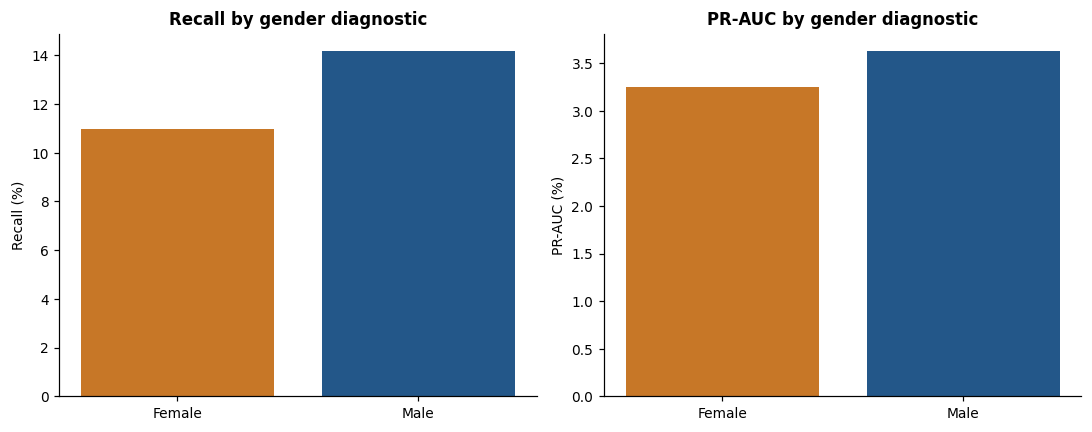

In [8]:
gender = fairness.query("attribute == 'gender'").copy()
display(fairness)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(gender.group, gender.recall * 100, color=[ORANGE, BLUE])
axes[0].set(title="Recall by gender diagnostic", ylabel="Recall (%)")
axes[1].bar(gender.group, gender.pr_auc * 100, color=[ORANGE, BLUE])
axes[1].set(title="PR-AUC by gender diagnostic", ylabel="PR-AUC (%)")
finish(fig, "07_fairness_gender")

## 25–27. Current scoring, capacity tiers, and observable signals

Only after frozen test evaluation were 29,360 current policies scored. Priority is the highest
10%, Watch the next 20%, and Routine the remaining 70%. Reason flags are observed servicing
signals—not SHAP values and not proof of why the model assigned a score.

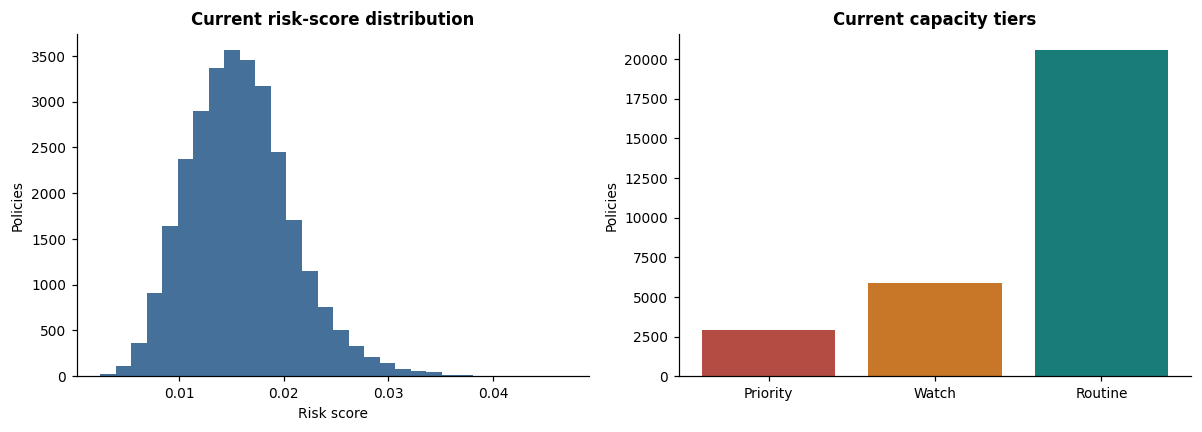

,policies
risk_tier,
Priority,2936
Watch,5872
Routine,20552


,policy_id,customer_id,agent_id,agency_unit_id,region,product_name,payment_frequency,policy_age_days,status_at_observation,risk_score,risk_percentile,risk_tier,observable_reason_flags
2,P000004,C017208,A0056,U010,Northern,Retirement Secure,Monthly,150,Active,0.024634,0.950102,Priority,Recent missed premium; Low recent payment comp...
8,P000012,C011638,A0395,U008,Western,Savings Growth,Quarterly,284,Active,0.024398,0.946049,Priority,No configured observable risk signal
10,P000014,C004994,A0060,U011,Northern,Protection Plus,Monthly,128,Active,0.025789,0.964578,Priority,High late-payment rate; Short policy tenure
11,P000015,C002860,A0345,U010,Northern,Retirement Secure,Monthly,106,Active,0.023480,0.930688,Priority,Short policy tenure
15,P000022,C002698,A0138,U008,Western,Protection Plus,Monthly,131,Active,0.024184,0.942916,Priority,Short policy tenure
21,P000028,C011689,A0136,U010,Northern,Savings Growth,Monthly,424,Grace,0.025135,0.956778,Priority,Currently in Grace
27,P000035,C000732,A0315,U007,Eastern,Savings Growth,Monthly,180,Active,0.026263,0.969210,Priority,Recent missed premium; Low recent payment comp...
46,P000058,C017399,A0169,U001,Central,Retirement Secure,Monthly,117,Active,0.023867,0.937670,Priority,High late-payment rate; Short policy tenure
55,P000069,C009078,A0069,U007,Eastern,Savings Growth,Semi-Annual,373,Active,0.024097,0.941587,Priority,Recent missed premium; Low recent payment comp...
57,P000071,C004200,A0193,U009,Western,Education Builder,Monthly,149,Active,0.024347,0.945300,Priority,Repeated late payments; High late-payment rate...


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(current_scores.risk_score, bins=30, color=BLUE, alpha=0.85)
axes[0].set(title="Current risk-score distribution", xlabel="Risk score", ylabel="Policies")
tier_order = ["Priority", "Watch", "Routine"]
tier_counts = current_scores.risk_tier.value_counts().reindex(tier_order)
axes[1].bar(tier_counts.index, tier_counts.values, color=[RED, ORANGE, TEAL])
axes[1].set(title="Current capacity tiers", ylabel="Policies")
finish(fig, "08_current_scores_tiers")
display(tier_counts.rename("policies").to_frame())
display(current_scores.query("risk_tier == 'Priority'").head(20))

## 28–30. Retention workflow, limitations, and interview summary

**Workflow:** score → prioritize → human review → customer outreach/service support → record
outcomes. Never use the output for automatic cancellation, pricing, benefit reduction, or
underwriting denial.

**Limitations:** synthetic generator structure, repeated policy observations, no agent-transfer
history, no real intervention outcomes, modest test ranking, material later-period
underprediction, and no causal interpretation.

**Interview summary:** “I reconstructed what was knowable at each month-end, trained only on past
periods, selected on validation, froze the model, tested once, and scored the current portfolio
afterward. The model provides modest top-K prioritization lift but underpredicts later absolute
risk, so I separate discrimination from calibration and frame scores for human retention review.”